# UCI Adult — calibration, threshold, and group audit

This stage uses only the official training split, divided into fit and calibration/validation partitions. The official test split remains reserved for final evaluation. Tables show uncertainty with Wilson intervals, but they do not by themselves establish acceptability or compliance.

In [1]:
from pathlib import Path
import sys
import pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == 'en-US' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from adult_data import load_adult
from validation_audit import write_validation_outputs
frame = load_adult(ROOT / 'data' / 'raw' / 'adult_uci')
outputs = write_validation_outputs(frame, ROOT / 'data' / 'processed' / 'validation')

## 1. Probabilistic performance on validation

ROC-AUC and PR-AUC measure ranking; Brier measures probability error. Decision metrics use 0.5 only as a reference, not as a selected threshold.

In [2]:
global_metrics = pd.read_csv(outputs['global_metrics'])
global_metrics.sort_values('roc_auc', ascending=False)

,model,threshold,roc_auc,pr_auc,brier,precision,recall_tpr,f1,selection_rate
3,hist_gradient_boosting,0.5,0.928213,0.833058,0.087381,0.784627,0.657526,0.715475,0.201750
2,random_forest,0.5,0.919201,0.807758,0.094590,0.777691,0.635842,0.699649,0.196837
1,logistic_regression,0.5,0.906815,0.772540,0.101257,0.742835,0.611607,0.670864,0.198219
0,dummy_prior,0.5,0.500000,0.240749,0.182789,0.000000,0.000000,0.000000,0.000000


### Insights:

HistGradientBoosting kept ROC-AUC of 0.928213, PR-AUC of 0.833058, and Brier of 0.087381 on this validation split. This is strong evidence of relative discrimination and probabilistic quality for this partition, but it is not final performance and does not justify a decision by itself.

## 2. Calibration check

We group probabilities into ten bands and compare mean predicted probability with observed frequency. Binning helps reveal misalignment but does not replace broader uncertainty analysis.

In [3]:
calibration_bins = pd.read_csv(outputs['calibration_bins'])
calibration_bins.query("model == 'hist_gradient_boosting'")

,model,bin,count,mean_predicted_probability,observed_rate,n_bins
20,hist_gradient_boosting,"(-0.0008, 0.00205]",652,0.000828,0.000000,10
21,hist_gradient_boosting,"(0.00205, 0.00769]",651,0.004820,0.003072,10
22,hist_gradient_boosting,"(0.00769, 0.0156]",651,0.011296,0.016897,10
23,hist_gradient_boosting,"(0.0156, 0.0321]",651,0.022193,0.023041,10
24,hist_gradient_boosting,"(0.0321, 0.0739]",652,0.050209,0.042945,10
25,hist_gradient_boosting,"(0.0739, 0.171]",651,0.115248,0.110599,10
26,hist_gradient_boosting,"(0.171, 0.327]",651,0.243675,0.247312,10
27,hist_gradient_boosting,"(0.327, 0.506]",651,0.410999,0.390169,10
28,hist_gradient_boosting,"(0.506, 0.767]",651,0.637565,0.632873,10
29,hist_gradient_boosting,"(0.767, 0.999]",652,0.931058,0.940184,10


### Insights:

Read this table as a comparison between predicted probability and observed frequency in each band, not as proof of perfect calibration. The next review should compare curves and intervals across models before selecting a candidate.

## 3. Threshold trade-off

The threshold grid shows how precision, recall, F1, and selection rate change. It makes the decision explicit; no threshold is selected here and the test split is not used.

The plots below show each metric that changes with the threshold separately. ROC-AUC, PR-AUC, and Brier are not plotted because they do not depend on the classification threshold.

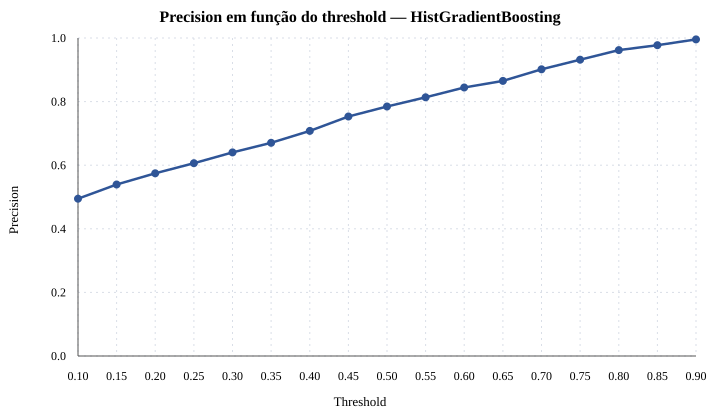

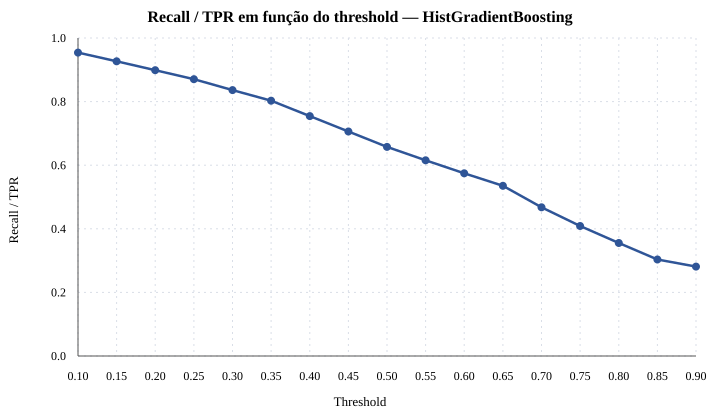

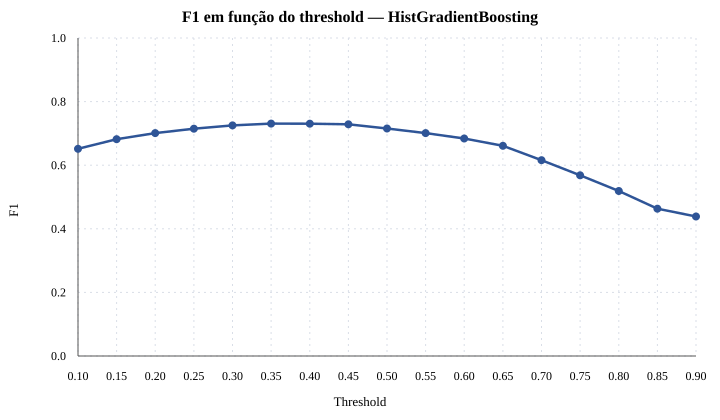

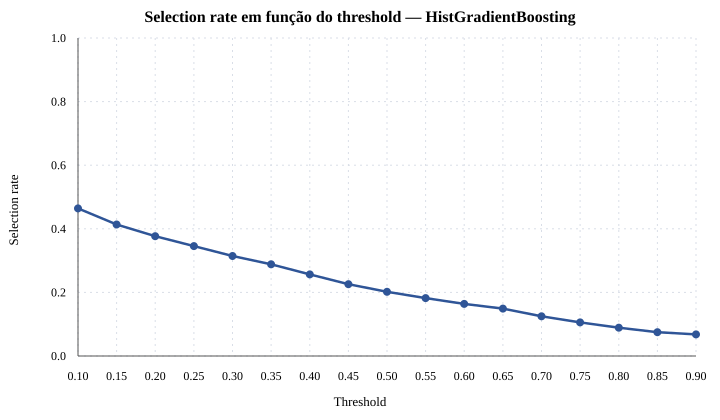

In [4]:
from IPython.display import SVG, display
from threshold_plots import build_threshold_metric_svgs
threshold_metrics = pd.read_csv(outputs['threshold_metrics'])
threshold_metrics_hgb = threshold_metrics.query("model == 'hist_gradient_boosting'").sort_values('threshold')
threshold_invariant_metrics = ['roc_auc', 'pr_auc', 'brier']
assert threshold_metrics_hgb[threshold_invariant_metrics].nunique().eq(1).all()
varying_metrics = {
    'precision': 'Precision',
    'recall_tpr': 'Recall / TPR',
    'f1': 'F1',
    'selection_rate': 'Selection rate',
}
threshold_metric_svgs = build_threshold_metric_svgs(
    threshold_metrics_hgb, varying_metrics, 'HistGradientBoosting'
)
for svg in threshold_metric_svgs.values():
    display(SVG(svg))

### Insights:

The 0.5 threshold remains provisional. A future choice must make the relative cost of false positives and false negatives explicit, consider metric stability, and examine group behavior instead of maximizing one metric in isolation.

## 4. Rate audit by sex, race, and intersection

At the reference threshold, we measure selection rate, TPR, FPR, FNR, and PPV by group. Wilson intervals make it visible when a difference depends on small denominators.

Following Wilson's 1927 treatment of inference for a binomial rate, the Wilson score interval incorporates the observed successes, failures, and sample size when locating the plausible range for the underlying proportion. In this notebook we use the 95% form with z = 1.96. This interval is preferable to treating a proportion as if its uncertainty were always symmetric and normal, especially for small groups or rates close to 0 or 1; it still describes sampling uncertainty only and does not account for multiple comparisons, dependence between records, or variation across dataset splits.

In the plots, the point represents the estimated rate and the horizontal bar represents the Wilson interval. The first block compares sex and race; the second shows sex × race intersections. The † mark identifies denominators below 30, which require cautious interpretation.

,model,threshold,audit_column,group,count,denominator,metric,estimate,ci_low,ci_high,low_support
5043,hist_gradient_boosting,0.5,race,Other,45,4,fnr,0.000000,0.000000,0.489900,True
5048,hist_gradient_boosting,0.5,race,White,5533,1410,fnr,0.337589,0.313376,0.362684,False
5033,hist_gradient_boosting,0.5,race,Asian-Pac-Islander,200,52,fnr,0.384615,0.264703,0.520404,False
5038,hist_gradient_boosting,0.5,race,Black,662,93,fnr,0.387097,0.294459,0.488692,False
5028,hist_gradient_boosting,0.5,race,Amer-Indian-Eskimo,73,9,fnr,0.555556,0.266647,0.811225,True
...,...,...,...,...,...,...,...,...,...,...,...
5096,hist_gradient_boosting,0.5,sex_race,Male × White,3807,1196,tpr,0.666388,0.639170,0.692540,False
5061,hist_gradient_boosting,0.5,sex_race,Female × Black,329,18,tpr,0.666667,0.437491,0.837214,True
5076,hist_gradient_boosting,0.5,sex_race,Male × Amer-Indian-Eskimo,45,5,tpr,0.800000,0.375528,0.963777,True
5066,hist_gradient_boosting,0.5,sex_race,Female × Other,11,1,tpr,1.000000,0.206543,1.000000,True


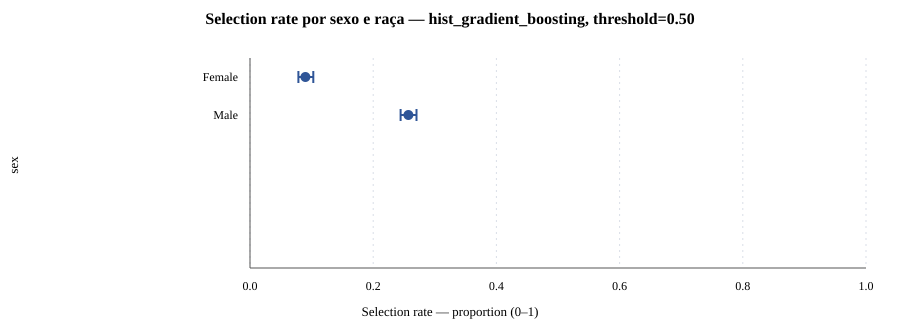

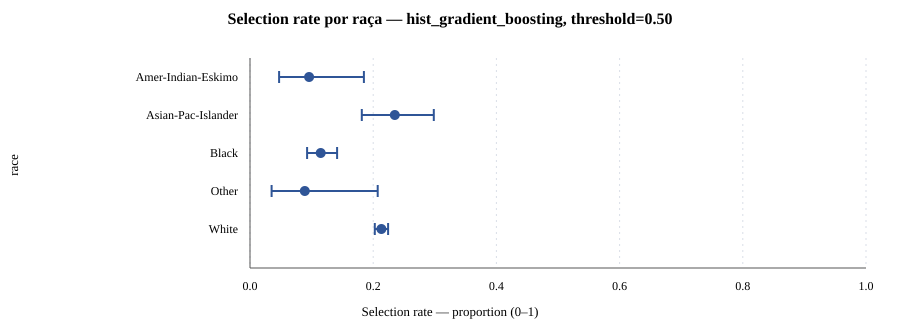

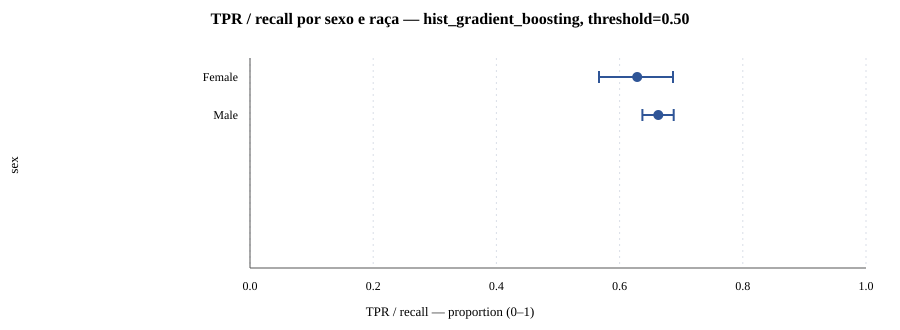

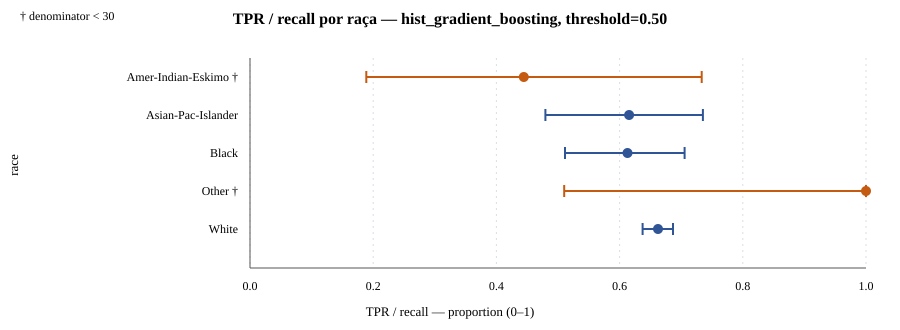

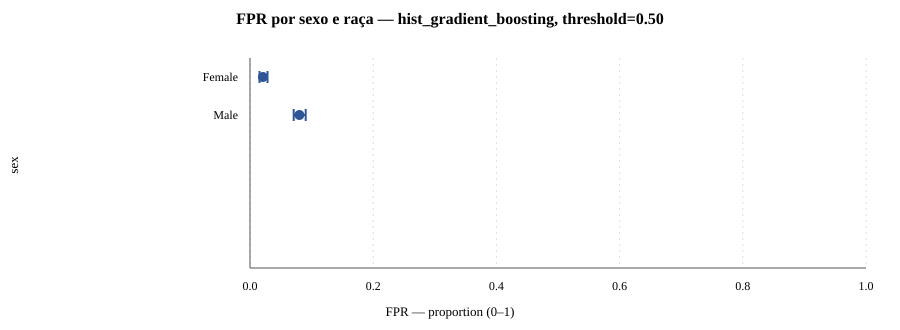

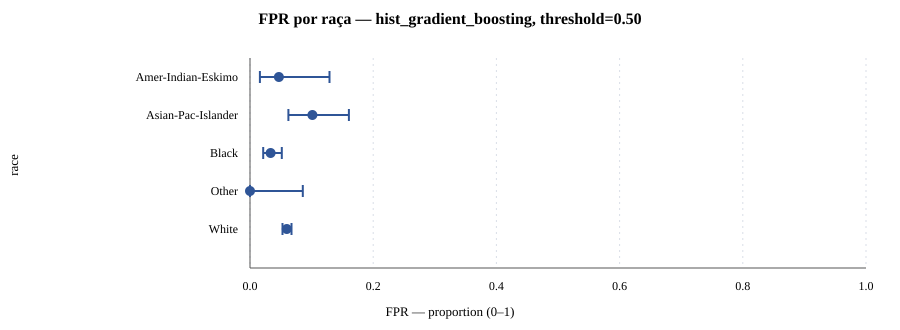

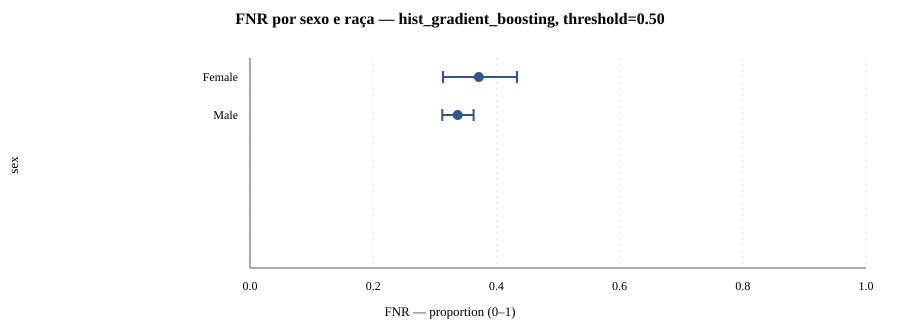

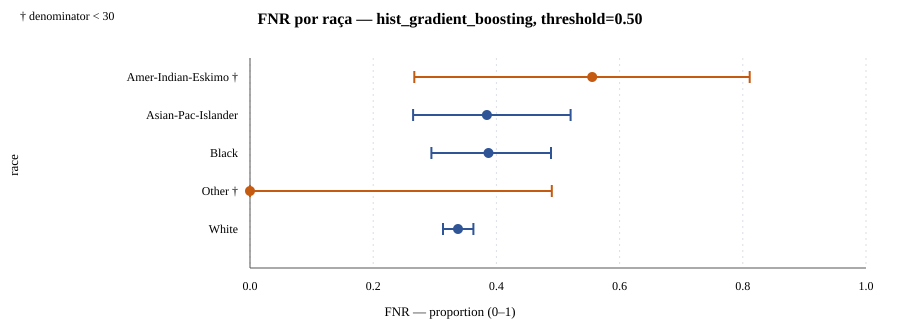

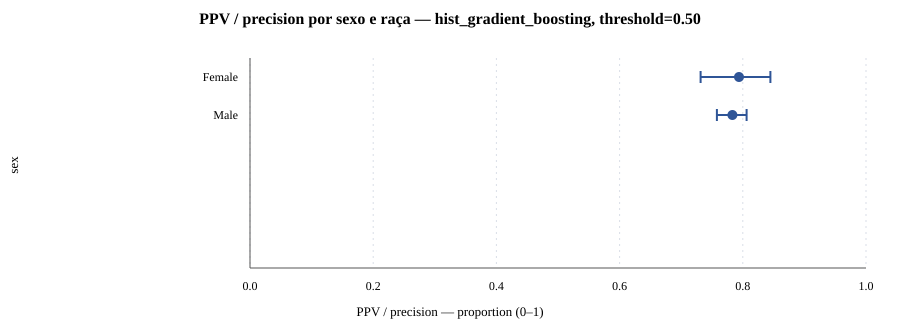

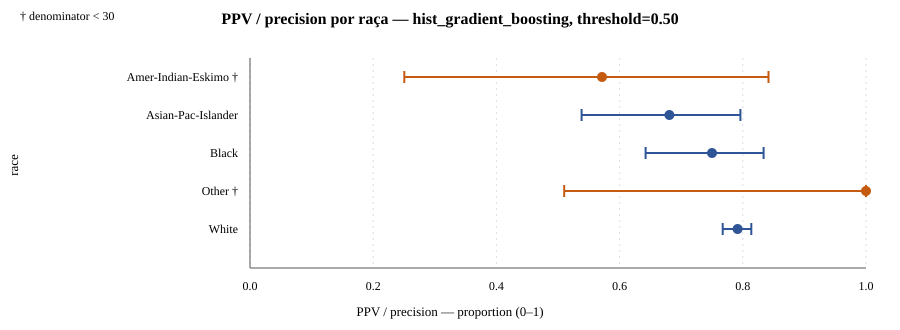

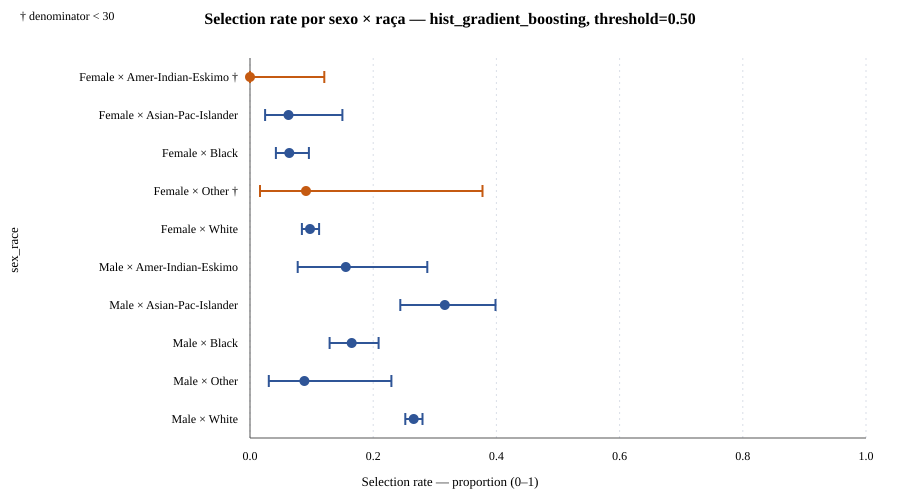

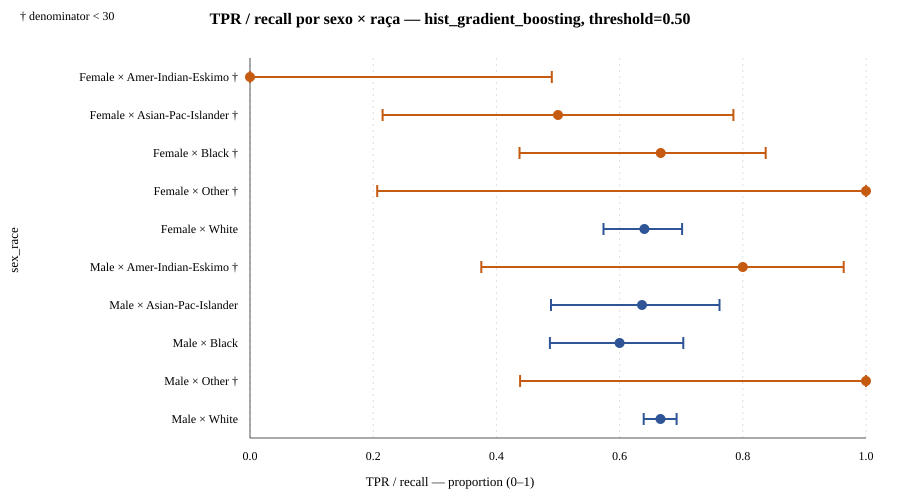

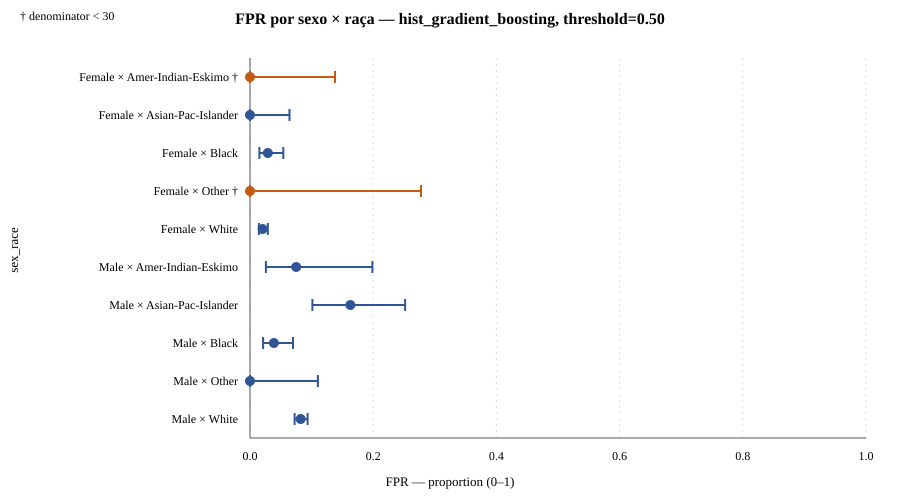

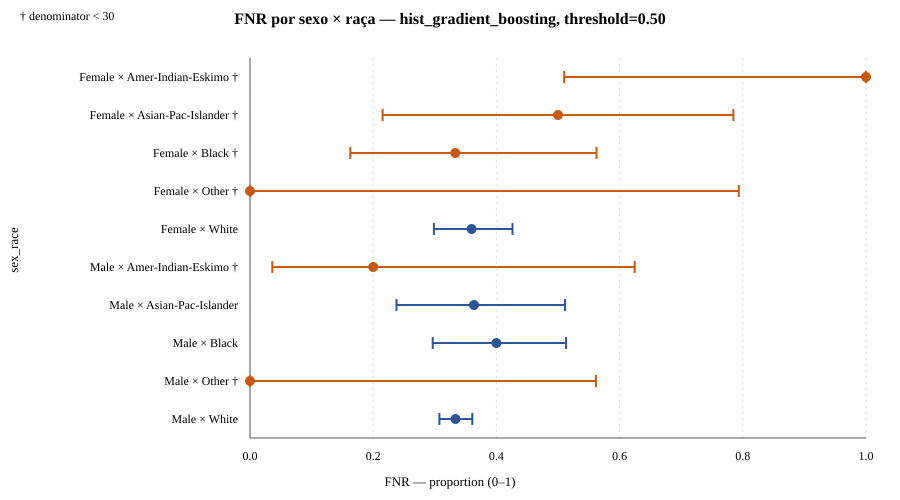

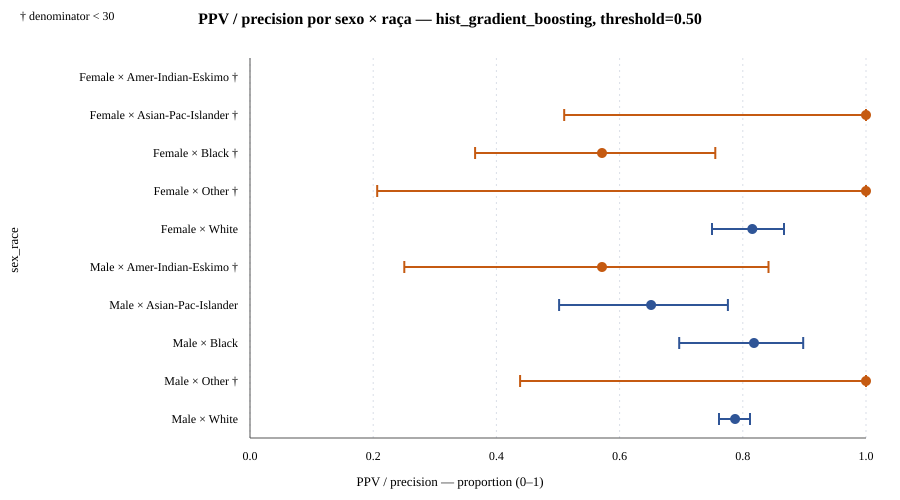

In [5]:
from IPython.display import SVG, display
from group_audit_plots import build_group_audit_svgs
group_metrics = pd.read_csv(outputs['group_metrics'])
metric_labels = {
    'selection_rate': 'Selection rate',
    'tpr': 'TPR / recall',
    'fpr': 'FPR',
    'fnr': 'FNR',
    'ppv': 'PPV / precision',
}
group_audit_svgs = build_group_audit_svgs(
    group_metrics, metric_labels, 'hist_gradient_boosting', 0.5
)
display(group_metrics.query("model == 'hist_gradient_boosting' and threshold == 0.5").sort_values(['audit_column', 'metric', 'estimate']))
for svg in group_audit_svgs['marginal'].values():
    display(SVG(svg))
for svg in group_audit_svgs['intersection'].values():
    display(SVG(svg))

### Insights:

At threshold 0.5, selection and error rates differ across sex, race, and intersections. Some intersections have small denominators and wide intervals; therefore observed disparity must not automatically become a causal or legal claim. Final decisions require comparing candidates, uncertainty, and the reserved official test.

## Methodological reference

Wilson, E. B. (1927). *Probable inference, the law of succession, and statistical inference*. **Journal of the American Statistical Association, 22**(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953

## Next step

Consolidate the selection protocol, justify a threshold under the risk framing, and only then run final evaluation on `adult.test`, followed by the model card and executive report.